# 5 · Validation — does the model tell the truth?

The football-recruitment DSS this project is measured against had one illustrative
case study and no validation section. Three checks here, each answering a question an
examiner would actually ask.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np, pandas as pd
from portscra.viz import PALETTE, INK_MUTED, style, label_bars, despine
style()

def short(text, limit=30):
    "Trim to a word boundary — a label cut mid-word reads as a rendering bug."
    if len(text) <= limit:
        return text
    cut = text[:limit].rsplit(" ", 1)[0]
    return (cut or text[:limit]) + "…"

In [2]:
from portscra.controls import CATALOGUE
from portscra.risk import RONNE_2024, OutageCostPerHour
from portscra.taxonomy import build_scenarios
from portscra.taxonomy.scenarios import SCENARIO_TEMPLATES
from portscra.validation import (INCIDENTS, compare_to_matrix, qualitative_score,
                                 rank_agreement, replay_incident)

cost = OutageCostPerHour(RONNE_2024)
scenarios = build_scenarios(cost)
by_id = {s.id: s for s in scenarios}
NAMES = {t.id: t.name for t in SCENARIO_TEMPLATES}

## 1 · Incident replay

Real port incidents have documented durations. Do they fall inside the model's
predicted band?

Incidents are split into those that **anchored** the estimates and those **held out**.
Only the held-out ones are evidence — checking a model against the data used to build
it is a consistency check, and reporting that as validation would be dishonest.

In [3]:
rows = []
for inc in INCIDENTS:
    r = replay_incident(by_id[inc.scenario_id], inc)
    rows.append({"incident": f"{inc.name} ({inc.year})",
                 "role": "anchor" if inc.used_as_anchor else "held out",
                 "observed": f"{inc.downtime_hours:.0f} h",
                 "model P10–P90": f"{r.p10:.0f}–{r.p90:.0f} h",
                 "percentile": f"{r.percentile:.0f}%",
                 "verdict": r.verdict})
pd.DataFrame(rows)

,incident,role,observed,model P10–P90,percentile,verdict
0,Port of Nagoya (LockBit) (2023),anchor,60 h,0–156 h,50%,inside P10-P90
1,DP World Australia (2023),anchor,72 h,0–156 h,56%,inside P10-P90
2,COSCO Americas (2018),held out,120 h,0–156 h,79%,inside P10-P90
3,Transnet (Durban and others) (2021),held out,120 h,0–156 h,79%,inside P10-P90
4,Port of Barcelona (2018),held out,0 h,0–156 h,0%,inside P10-P90
5,Port of San Diego (2018),held out,0 h,0–156 h,0%,inside P10-P90


**The first run of this failed 2 of 4, and the failure was the most useful thing the
project produced.**

Barcelona and San Diego (both 2018) suffered ransomware *without stopping the quay* —
IT was hit, ships kept working. The downtime estimate had a floor of 24 hours and
could not produce that outcome at any percentile. The model was asserting that
supplier-borne ransomware always becomes an operational outage, which the record
contradicts.

The fix was structural rather than a parameter nudge: `disruption_probability` now
separates *an incident happened* from *operations stopped*. Simply lowering the floor
would have blurred two distinct things together.

In [4]:
s2 = by_id["S2"]
modelled = 1 - s2.loss_magnitude.disruption_probability
s2_incidents = [i for i in INCIDENTS if i.scenario_id == "S2"]
observed = sum(1 for i in s2_incidents if i.downtime_hours == 0) / len(s2_incidents)
print("Share of ransomware events causing NO operational downtime")
print(f"  model     {modelled:.0%}")
print(f"  observed  {observed:.0%}  ({sum(1 for i in s2_incidents if i.downtime_hours==0)} "
      f"of {len(s2_incidents)} documented incidents)")

Share of ransomware events causing NO operational downtime
  model     33%
  observed  33%  (2 of 6 documented incidents)


Band containment is a weak test once the band starts at zero. Matching the *rate* at
which nothing operational happens is not — and it is the parameter the replay forced
into existence.

## 2 · Against a 5×5 risk matrix

A qualitative matrix is what CSET, MONARC and most port risk registers actually
produce. Both methods are fed the *same* underlying estimates, so the comparison
isolates the method rather than the inputs.

In [5]:
from portscra.controls.optimiser import scenario_ale
rows = [{"scenario": NAMES[s.id][:44],
         "matrix": f"{qualitative_score(s).rating} ({qualitative_score(s).score})",
         "quantitative ALE": f"EUR {scenario_ale(s):,.0f}"}
        for s in sorted(scenarios, key=lambda s: -qualitative_score(s).score)]
print(f"rank agreement with the quantitative ordering: {rank_agreement(scenarios):+.2f}\n")
pd.DataFrame(rows)

rank agreement with the quantitative ordering: +0.91



,scenario,matrix,quantitative ALE
0,SaaS account takeover leading to invoice fra,Medium (9),"EUR 33,493"
1,Managed service provider compromise leading,Medium (8),"EUR 25,714"
2,"OT and IoT compromise of gates, cranes or CC",Medium (6),"EUR 10,163"
3,AIS and GNSS spoofing or jamming,Medium (6),"EUR 7,888"
4,Compromised freeware or open-source dependen,Medium (6),"EUR 10,816"
5,Vendor data breach exposing port data and cr,Medium (6),"EUR 18,422"
6,Trojanized update to terminal or port commun,Low (3),"EUR 4,688"


Rank agreement is **+0.91** — the matrix *orders* risks perfectly sensibly. If it did
not, beating it would prove nothing. The interesting claim is that a method can rank
well and still allocate badly.

Six of seven scenarios land in a single "Medium" band spanning 4.2× in expected loss.
That is Cox's *range compression*, and it is why a heat map cannot prioritise
spending.

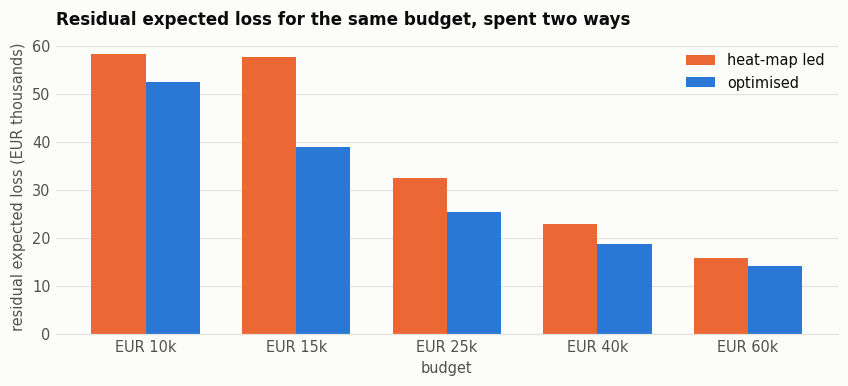

  EUR 10,000  advantage EUR   6,002  (+5% of baseline)
  EUR 15,000  advantage EUR  18,856  (+17% of baseline)
  EUR 25,000  advantage EUR   6,960  (+6% of baseline)
  EUR 40,000  advantage EUR   4,232  (+4% of baseline)
  EUR 60,000  advantage EUR   1,644  (+1% of baseline)


In [6]:
budgets = [10_000, 15_000, 25_000, 40_000, 60_000]
comparisons = [compare_to_matrix(scenarios, CATALOGUE, b) for b in budgets]

fig, ax = plt.subplots(figsize=(7.8, 3.6))
x = np.arange(len(budgets)); w = 0.36
b1 = ax.bar(x - w/2, [c.matrix_residual/1000 for c in comparisons], w,
            color=PALETTE["orange"], label="heat-map led")
b2 = ax.bar(x + w/2, [c.quantitative_residual/1000 for c in comparisons], w,
            color=PALETTE["blue"], label="optimised")
ax.set_xticks(x); ax.set_xticklabels([f"EUR {b//1000}k" for b in budgets])
ax.set_title("Residual expected loss for the same budget, spent two ways")
ax.set_ylabel("residual expected loss (EUR thousands)"); ax.set_xlabel("budget")
ax.legend(loc="upper right")
despine(ax); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

for b, c in zip(budgets, comparisons):
    print(f"  EUR {b:>6,}  advantage EUR {c.advantage:>7,.0f}  "
          f"({c.advantage_pct:+.0%} of baseline)")

The optimiser wins at every budget, by €1.6k–18.9k a year. *A matrix can rank well
and still allocate badly*, because it cannot see that a cheap control touching four
amber risks beats an expensive one touching a single red.

## 3 · ENISA maturity — phase four

This project claims to operationalise ENISA's four-phase approach. Phases one to three
are the taxonomy, the risk engine and the optimiser. This is the fourth.

The portfolio implies a maturity profile, so a budget can be read in ENISA's terms as
well as in euro.

In [7]:
from portscra.controls import optimise
from portscra.maturity import CATEGORY_NAMES, maturity_from_controls

for budget in (0, 25_000, sum(c.annual_cost_eur for c in CATALOGUE)):
    p = optimise(scenarios, CATALOGUE, budget)
    profile = maturity_from_controls([c.id for c in p.controls])
    cats = " · ".join(f"{CATEGORY_NAMES[k][:14]} {v:.2f}"
                      for k, v in sorted(profile.by_category().items()))
    print(f"EUR {budget:>7,.0f} -> overall {profile.overall:.2f}/3  "
          f"(supply-chain {profile.supply_chain_score():.2f})")
    print(f"             {cats}")

EUR       0 -> overall 0.00/3  (supply-chain 0.00)
             Organisational 0.00 · Policies 0.00 · Technical meas 0.00
EUR  25,000 -> overall 1.17/3  (supply-chain 1.00)
             Organisational 1.25 · Policies 1.75 · Technical meas 0.50
EUR 142,500 -> overall 2.42/3  (supply-chain 2.67)
             Organisational 2.50 · Policies 1.75 · Technical meas 3.00


Buying **every** control still reaches only 2.42 of 3. That ceiling is deliberate:
ENISA is explicit that maturity cannot be achieved through a checklist mentality.
Level 3 requires oversight, testing and continuous improvement — a way of working
rather than a purchase. A model that let a port buy its way to *Optimal* would be
misrepresenting the framework it cites.

---

## What this project concluded

* **The tail is stickier than the mean.** A portfolio buys frequency reduction; the
  bad year that still happens stays expensive. Reporting the mean overstates the
  protection bought.
* **Buying everything is worse than buying the right subset** — ROSI turns negative at
  full-catalogue spend.
* **Deriving the hourly cost reordered the risks.** Invoice fraud overtook ransomware
  once the figure came from audited accounts rather than a plausible guess.
* **Held-out validation found a real defect**, and fixing it lowered the model's own
  expected-loss estimate. A validation suite that never fails is not a validation
  suite.